# Practice Session 02: Networks from text

*Introduction to Network Science* (2026/27), UPF

Author: <font color="blue">Pol Rovira Almirall</font>

E-mail: <font color="blue">pol.rovira02@estudiant.upf.edu</font>

Date: <font color="blue">21/10/2026</font>

# 1. Create the directed mention network

In [ ]:
import io
import json
import gzip
import csv
import re

In [3]:
# Input file
COMPRESSED_INPUT_FILENAME = "data/CovidLockdownCatalonia.json.gz"   # You may need to change this filepath depending on where you've saved the data file

# These are the output files, leave as-is
OUTPUT_ALL_EDGES_FILENAME = "CovidLockdownCatalonia.csv"
OUTPUT_FILTERED_EDGES_FILENAME = "CovidLockdownCatalonia-min-weight-filtered.csv"
OUTPUT_CO_MENTIONS_FILENAME = "CovidLockdownCatalonia-co-mentions.csv"

## 1.1. Extract mentions

In [4]:
# Leave this code as-is

def extract_mentions(text):
    return re.findall("@([a-zA-Z0-9_]{5,20})", text)

print(extract_mentions("RT @elnacionalcat: check this post by @en_blau"))

['elnacionalcat', 'en_blau']


## 1.2. Count mentions


In [5]:
mentions_counter={}

with gzip.open(COMPRESSED_INPUT_FILENAME, "rt", encoding="utf-8") as input_file:
    for i in input_file: #repassem fila per fila
        tweet=json.loads(i)
        author= tweet['user']['screen_name']
        mentions= extract_mentions(tweet['full_text'])
        print(author, mentions)
        for mention in mentions:
            clau= (author, mention)
            #.get(clau,0) retorna 0 si parella nova i li afegeix 1 després
            mentions_counter[clau]= mentions_counter.get(clau, 0) + 1

    

Old_Nemo ['aramateix', 'govern']
rhinomni ['RBReich']
ForquillaBDN ['Totbadalona']
ZainulAriffn ['rafiziramli']
sarizor ['gominolasdpetro']
potasini []
lunavegan ['borisbarrera']
XaviMarti5 ['XSalaimartin']
Gotirb ['nichcarlson']
EP_internac_cas []
AldaayFlorencia []
suruasinoiD ['marctarinmarti']
GuifrePpcc ['MACanadell']
Lajurita ['boticariagarcia']
marta_ter ['EmilioMorenatti']
AndreuCriquet ['decaminoapekin']
LLUISNARO ['angeliufus']
SpanishDan1 ['Pumpkinz16']
tutmosh ['brasil247']
JavierBcn72 ['FincaSantaMarga']
annetakawaii ['XSalaimartin']
emicaza ['SaludPublicaEs']
PregonerSantEst ['polispol']
irisgonzalezaf ['ChicoMeteoro']
maarinaacastroo ['Rodrigotb__']
jdc_jesu ['Sayo_cab75']
volscanti []
jlvndr ['GillianHTurner']
annamfabra ['javihdez']
Carrerasxavi ['HectorPumo']
JorginaMarser ['IldeVrMy', 'pr_soc']
mirovira75 ['jhergony']
BiureRaich ['VilaWeb']
PAULALVAREZ5 ['gabrielrufian']
ea3fo ['VilaWeb', 'vpartal']
funny_rodriguez ['elsquissos']
RaquelEnrich ['Xlapitz']
el_nucli []


In [6]:
print(mentions_counter[('joanmariapique', 'catalangov')])

9


In [7]:
for (u,v) in mentions_counter:
    if u < v and (v,u) in mentions_counter:
        # apliquem sumatòri per tal de distingir quan un menciona que quan és mencionat
        total = mentions_counter[(u,v)] + mentions_counter[(v, u)]
        if total > 8:
            print(f"Accounts @{u} and @{v} mention each other {total} times")



## 1.3 Save network

In [40]:
# Leave this code as-is

lines_written = 0

with io.open(OUTPUT_ALL_EDGES_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for key in mentions_counter:
        author = key[0]
        mention = key[1]
        weight = mentions_counter[key]
        writer.writerow([author, mention, weight])
        lines_written += 1

print(f"Escrites {lines_written} línies al file {OUTPUT_ALL_EDGES_FILENAME}")

Escrites 34040 línies al file CovidLockdownCatalonia.csv


In [39]:
lines_written = 0

with io.open(OUTPUT_FILTERED_EDGES_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for key in mentions_counter:
        author = key[0]
        mention = key[1]
        weight = mentions_counter[key]
        if weight>=3: #afegim aquest weight per tenir només les arestes amb pes.
            writer.writerow([author, mention, weight])
            lines_written += 1

print(f"Escrites {lines_written} línies al file {OUTPUT_FILTERED_EDGES_FILENAME}")

Escrites 255 línies al file CovidLockdownCatalonia-min-weight-filtered.csv


# 2. Visualize the directed mention network


In [10]:
# Import required packages

import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
#obrim el graf i comptem nodes i arestes
g=nx.DiGraph()

with open(OUTPUT_FILTERED_EDGES_FILENAME, "r") as input_file:
    reader = csv.DictReader(input_file, delimiter='\t')
    for fila in reader:
        
        g.add_edge(fila['Source'], fila['Target'], weight=int(fila['Weight']))

print(f"Nodes: {g.number_of_nodes()}, arestes: {g.number_of_edges()}")


Nodes: 357, arestes: 255


In [12]:
# Leave this code as-is

list(nx.get_edge_attributes(g, 'weight').items())[:10]

[(('AlfonsGorina', 'movieweb'), 5),
 (('McIslamofobia', 'carlesplb'), 3),
 (('marsicilia', 'javiernegre10'), 4),
 (('wualaswold1', 'updayESP'), 9),
 (('RedPillDetox', 'TomthunkitsMind'), 7),
 (('SpanishDan1', 'fascinatorfun'), 8),
 (('SpanishDan1', 'g_gosden'), 6),
 (('SpanishDan1', 'BorisJohnson'), 4),
 (('SpanishDan1', 'miffythegamer'), 6),
 (('SpanishDan1', 'Haggis_UK'), 4)]

## 2.1. Extract the largest connected component using NetworkX

In [13]:
# Leave this code as-is

print(f"The network is weakly connected: {nx.is_weakly_connected(g)}")
print(f"The network is strongly connected: {nx.is_strongly_connected(g)}")

The network is weakly connected: False
The network is strongly connected: False


In [ ]:
#Després de fer el lcc el que fem és comptar els nodes i arestes d'aquest
lcc_nodes= max(nx.weakly_connected_components(g),key=len)

lcc = g.subgraph(lcc_nodes).copy()

print(f"LCC: {lcc.number_of_nodes()} nodes, {lcc.number_of_edges()} arestes")

LCC: 90 nodes, 95 arestes


In [15]:
# Leave this code as-is

print(f"The network is weakly connected: {nx.is_weakly_connected(lcc)}")
print(f"The network is strongly connected: {nx.is_strongly_connected(lcc)}")

The network is weakly connected: True
The network is strongly connected: False


## 2.2. Visualize the largest connected component


Create a plot with the largest connected component (`lcc`) using a spring (force-directed) layout.

To make the visualization more intuitive, you should take into account the betweenness of edges as an attribute to the layout algorithm and edge styles, as described below.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

First, calculate the betweenness of all edges in the `lcc` and add it as an attribute `betweenness` to the edges (like `weight` is currently). Take the "weight" attribute into account for the betweenness calculation. Check the `networkx` documentation for a function that you can use to calculate the edge betweenness centrality.

Since we have a small, weakly connected network, and we will use the betweenness for visualization purposes only, calculate it on the underirected version of the network. You can use `lcc.to_undirected()`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to add the edge betweenness as an attribute to the edges in `lcc`.</font>


In [16]:
lcc_no_direccionada=lcc.to_undirected() 
edge_betweenness = nx.edge_betweenness_centrality(lcc_no_direccionada, weight='weight')
#provem les arestes dirigides en les dues direccions
for u,v in lcc.edges():
    valor=edge_betweenness.get((u,v), edge_betweenness.get((v,u)))
    lcc[u][v]['betweenness']= valor

The below code outputs the top 10 edges by betweenness.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [17]:
# Leave this code as-is

top_edges = sorted(lcc.edges(data=True), key=lambda x: x[2]['betweenness'], reverse=True)[:10]
for edge in top_edges:
    print(f"Edge from @{edge[0]} to @{edge[1]} has betweenness {edge[2]['betweenness']:.3f}")

Edge from @joanmariapique to @sanchezcastejon has betweenness 0.347
Edge from @joanmariapique to @emergenciescat has betweenness 0.345
Edge from @EmDicMerce to @sanchezcastejon has betweenness 0.298
Edge from @EmDicMerce to @elnacionalcat has betweenness 0.273
Edge from @emocionycambio to @emergenciescat has betweenness 0.182
Edge from @joanmariapique to @QuimTorraiPla has betweenness 0.173
Edge from @bruixasirenil to @sanchezcastejon has betweenness 0.169
Edge from @enricgari to @QuimTorraiPla has betweenness 0.129
Edge from @enricgari to @VilaWeb has betweenness 0.124
Edge from @bruixasirenil to @govern has betweenness 0.118


Now we will plot the largest connected component using `networkx` and style it.

Generating good layouts to plot networkx graphs can be tricky. For this first example, you are given the code to generate a suitable layout for this network using an algorithm of the (familiar) force-directed layout type.

Later on, you will need to generate layouts yourself, so take some time to read the code below and check out what the parameters are for [`nx.spring_layout`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.layout.spring_layout.html).

Note in particular how the `weight` parameter works. (This is the reason why we added the betweenness as an attribute to the network.)

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [18]:
# Leave this code as-is (for now)

pos = nx.spring_layout(     # The function returns a dictionary with node positions (2D coordinates)...
    lcc,                    # ...for nodes in the largest connected component...
    weight='betweenness',   # ...using edge betweenness as an attractive force...
    method='energy',        # ...using the energy minimization method (see documentation for details)...
    k=0.1,                  # ...with a custom setting for the optimal distance between nodes.
    seed=42)

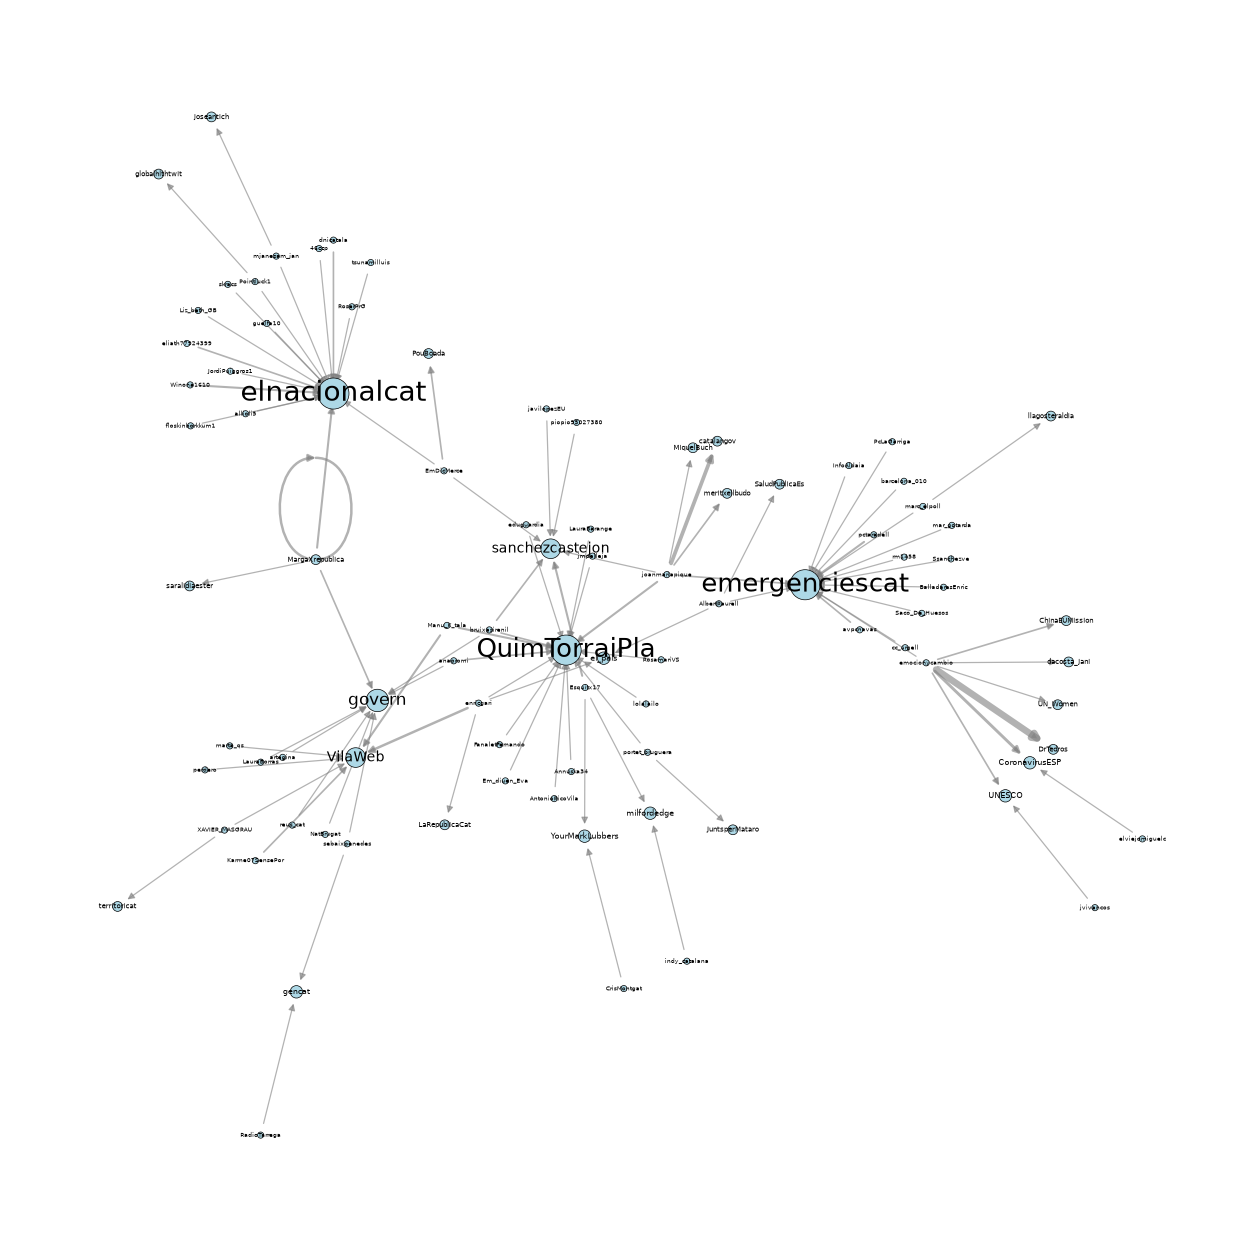

In [19]:
nodes= list(lcc.nodes())
edges= list(lcc.edges())
degree= dict(lcc.in_degree()) #grau d'entrada
weights =[]
for u,v in edges:
    w=lcc[u][v]['weight']
    weights.append(w) #afegim al final
node_sizes = [20 + 30 * degree[n] for n in nodes]   # mida ~ in-degree
edge_widths = [0.3 * w for w in weights]            # gruix ~ pes

plt.figure(figsize=(16, 16))

nx.draw_networkx_nodes(lcc, pos, nodelist=nodes, node_size=node_sizes,
                       node_color='lightblue', edgecolors='black', linewidths=0.5)
nx.draw_networkx_edges(lcc, pos, edgelist=edges, width=edge_widths,
                       arrows=True, arrowstyle='-|>', arrowsize=10,
                       edge_color='gray', alpha=0.6)

# Etiquetes una per una perquè la mida de lletra depèn de l'in-degree
for n in nodes:
    nx.draw_networkx_labels(lcc, pos, labels={n: n}, font_size=4 + degree[n])

plt.axis('off')
plt.savefig("mentions-largest-cc.png", dpi=300, bbox_inches='tight')
plt.show()


In [20]:
#diametre
diameter=nx.diameter(lcc.to_undirected())
print(f"Diàmetre de la LCC és {diameter}")
#mida (nodes i percentatge)
nombre_lcc=lcc.number_of_nodes()
nombre_total=g.number_of_nodes()
print(f"LCC:{nombre_lcc} nodes,{100*nombre_lcc/nombre_total:.1f}% dels nodes totals")
components=sorted(nx.weakly_connected_components(g),key=len, reverse=True)
print(f"La segona component és de {len(components[1])} nodes")
print(len(components))

Diàmetre de la LCC és 10
LCC:90 nodes,25.2% dels nodes totals
La segona component és de 17 nodes
112


En aquest graf trobem un 25% de nodes en el LCC és un valor realment gran dins de la quantitat de components que tenim. Això significa que hi ha moltes components petites. Tenim un diàmetre realment gran si el comparem amb la quantitat de nodes que te el nostre LCC. També veiem que té una estructura on hi ha un LCC grós però la resta de components connexos són petit poc enllaçats entre ells.

Ens surt el graf girat, és a dir, el que hi havia a la dreta, molta part ha passat a l'esquerra i a la inversa també, s'ens ha mantigut el node central igual però els altres dos que estaven menys centrats s'han desplaçat completament. Aleshores entenc que el que fa és exactament això, mantenir el graf de manera estructurada


## 2.3. Examine degree distributions


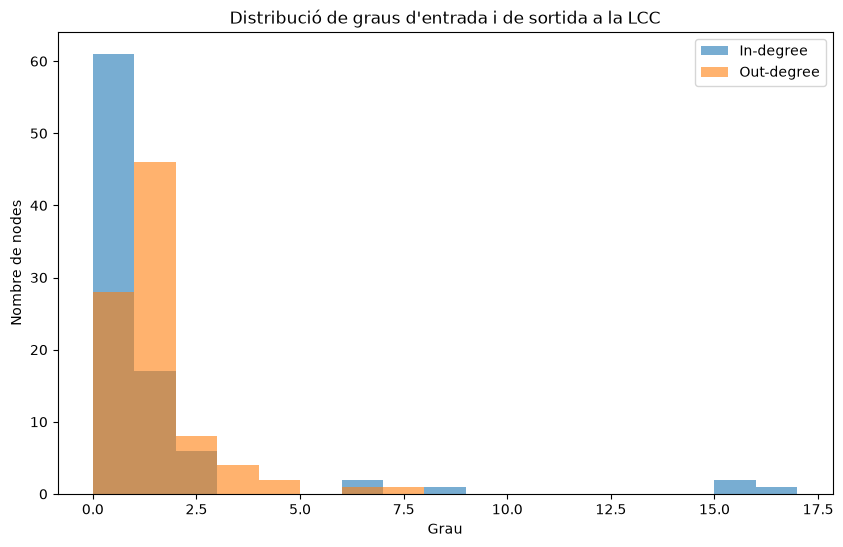

In [24]:
in_degrees =[]
out_degrees =[]
for n in lcc.nodes():
    in_degrees.append(lcc.in_degree(n)) #afegim els que entren
    out_degrees.append(lcc.out_degree(n)) #afegim els que surten
plt.figure(figsize=(10, 6))

max_deg = max(max(in_degrees), max(out_degrees))
bins = range(0, max_deg + 2)      # una barra per cada valor de grau

plt.hist(in_degrees, bins=bins, alpha=0.6, label='In-degree')
plt.hist(out_degrees, bins=bins, alpha=0.6, label='Out-degree')

plt.xlabel('Grau')
plt.ylabel('Nombre de nodes')
plt.title("Distribució de graus d'entrada i de sortida a la LCC")
plt.legend()
plt.show()


Veiem un histograma amb bastant sentit, el que veiem molt clar és que el grau de in_degree en casos és molt més alt i quan el grau és més baix trobem més out_degree això vol dir que hi ha estrelles on els hi arriba molts nodes i treuen molts out_degrees repartits


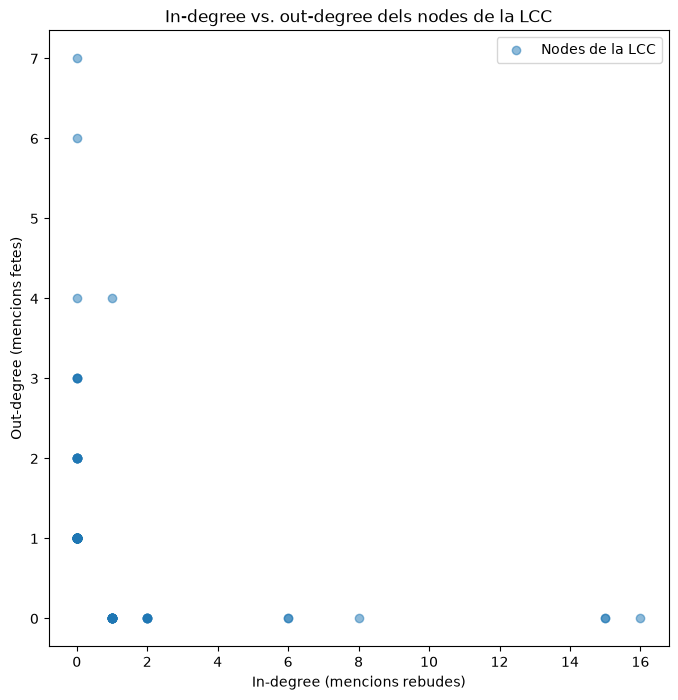

In [25]:
plt.figure(figsize=(8, 8))

plt.scatter(in_degrees, out_degrees, alpha=0.5, label='Nodes de la LCC')

plt.xlabel("In-degree (mencions rebudes)")
plt.ylabel("Out-degree (mencions fetes)")
plt.title("In-degree vs. out-degree dels nodes de la LCC")
plt.legend()
plt.show()

Al diagrama de dispersió podem veure que tots els nodes es troben molt aprop dels eixos, tenen un grau molt alt en una o un molt alt en l'altra. O els nodes reben molta informació i n'envien poca o envien poca i reben molta.


# 3. Create the undirected co-mention network


In [30]:
co_mentions_counter={}
with gzip.open(COMPRESSED_INPUT_FILENAME, "rt", encoding="utf-8") as input_file:
    for i in input_file:
        tweet = json.loads(i)
        mentions= set(extract_mentions(tweet['full_text']))
    #recorrem al complet l'array
        for i in mentions:
            for j in mentions:
                if i<j: #cada parella 1 vegada
                    clau=(i,j)
                    co_mentions_counter[clau]=co_mentions_counter.get(clau,0)+1



In [31]:
# Leave this code as-is

print(co_mentions_counter[('educaciocat', 'elnacionalcat')])

4


In [34]:
for (user1, user2) in co_mentions_counter:
    weight = co_mentions_counter[(user1, user2)]
    if weight >= 20:
        print(f"Comptes @{user1} i @{user2} estan comencionades {weight} vegades")

Comptes @VilaWeb i @mossos estan comencionades 20 vegades
Comptes @QuimTorraiPla i @govern estan comencionades 91 vegades
Comptes @sanchezcastejon i @tjparfitt estan comencionades 28 vegades
Comptes @elnacionalcat i @joseantich estan comencionades 90 vegades
Comptes @QuimTorraiPla i @tjparfitt estan comencionades 59 vegades
Comptes @QuimTorraiPla i @sanchezcastejon estan comencionades 24 vegades
Comptes @emergenciescat i @govern estan comencionades 31 vegades
Comptes @josepcosta i @sanchezcastejon estan comencionades 49 vegades
Comptes @eldiarioes i @iescolar estan comencionades 28 vegades
Comptes @gencat i @govern estan comencionades 62 vegades
Comptes @mossos i @semgencat estan comencionades 44 vegades
Comptes @elnacionalcat i @juansrod1 estan comencionades 30 vegades
Comptes @QuimTorraiPla i @emergenciescat estan comencionades 75 vegades
Comptes @Antoni_Gelonch i @sanchezcastejon estan comencionades 106 vegades


In [35]:
# Escrivim totes les co-mencions en un fitxer separat per tabuladors
lines_written = 0

with io.open(OUTPUT_CO_MENTIONS_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for (user1, user2), weight in co_mentions_counter.items():
        writer.writerow([user1, user2, weight])
        lines_written += 1

print(f"Escrites {lines_written} files al file {OUTPUT_CO_MENTIONS_FILENAME}")

Escrites 7816 files al file CovidLockdownCatalonia-co-mentions.csv


# 4. Visualize the undirected co-mention network 

Nodes: 4008, arestes: 7816
Subgraf: 138 nodes, 1823 arestes


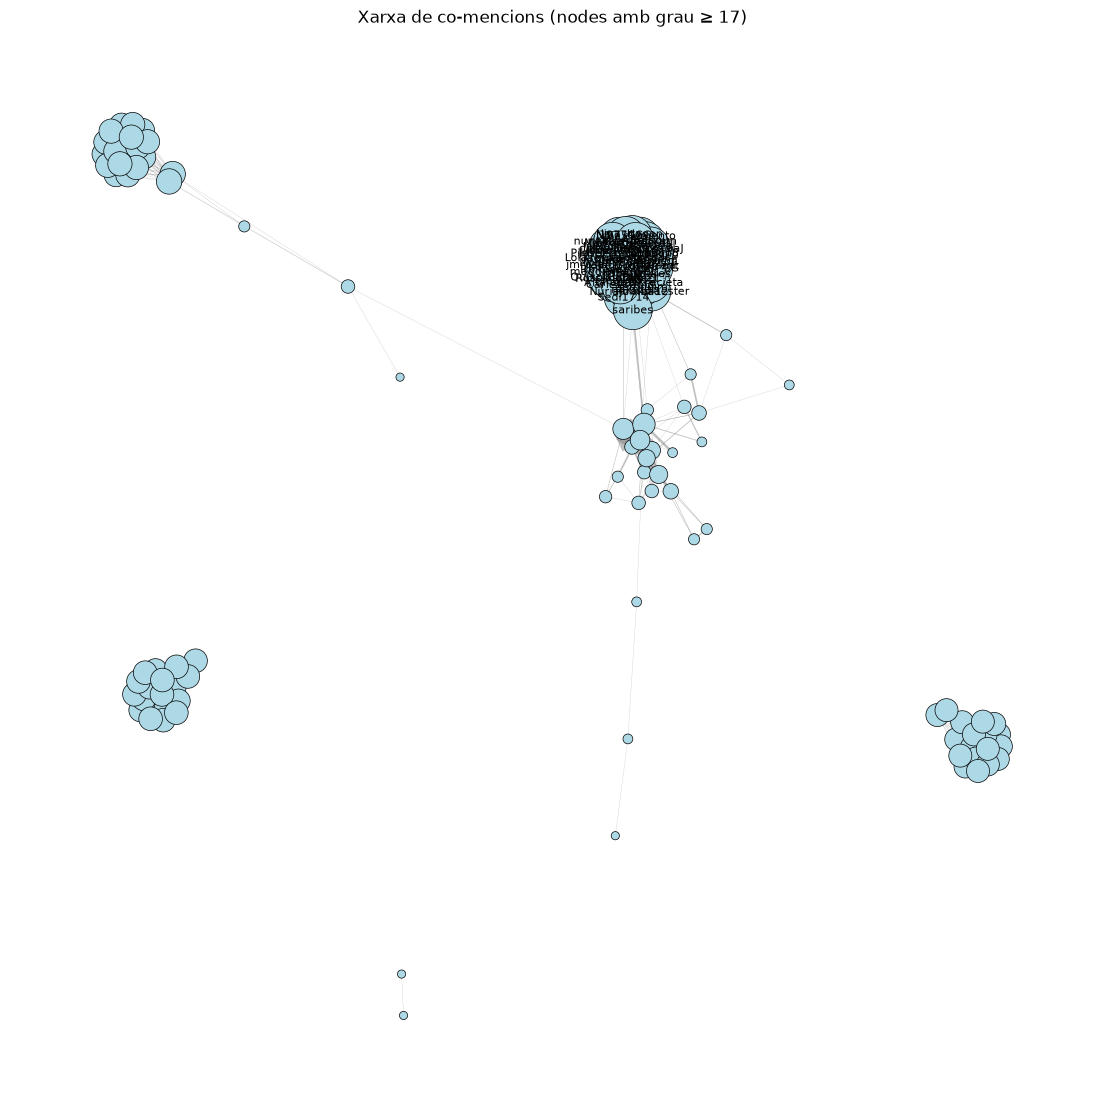

In [37]:
g_co = nx.Graph()

with open(OUTPUT_CO_MENTIONS_FILENAME, "r") as input_file:
    reader = csv.DictReader(input_file, delimiter='\t')
    for i in reader:
        g_co.add_edge(i['Source'], i['Target'], weight=int(i['Weight']))

print(f"Nodes: {g_co.number_of_nodes()}, arestes: {g_co.number_of_edges()}")
#agafem només els nodes alts
high_degree_nodes=[] 
for n in g_co.nodes():
    if g_co.degree(n) >= 17:
        high_degree_nodes.append(n)
sub = g_co.subgraph(high_degree_nodes).copy()
print(f"Subgraf: {sub.number_of_nodes()} nodes, {sub.number_of_edges()} arestes")
#calcular el layout
pos_co = nx.spring_layout(
    sub,
    weight='weight',   
    k=0.3,             
    iterations=100,    
    seed=42             
)
nodes = list(sub.nodes())
edges = list(sub.edges())

node_sizes = [20 + 15 * sub.degree(n) for n in nodes]               
edge_widths = [0.2 * sub[u][v]['weight'] for u, v in edges] 
# Dibuix
plt.figure(figsize=(14, 14))

nx.draw_networkx_edges(sub, pos_co, edgelist=edges, width=edge_widths,
                       edge_color='gray', alpha=0.5)
nx.draw_networkx_nodes(sub, pos_co, nodelist=nodes, node_size=node_sizes,
                       node_color='lightblue', edgecolors='black', linewidths=0.5)

# Etiquetes només per als nodes amb més grau, perquè el dibuix sigui llegible
labels = {}
for n in nodes:
    if sub.degree(n) >= 25:
        labels[n] = n
nx.draw_networkx_labels(sub, pos_co, labels=labels, font_size=8)

plt.axis('off')
plt.title("Xarxa de co-mencions (nodes amb grau ≥ 17)")
plt.savefig("co-mentions-network.png", dpi=300, bbox_inches='tight')
plt.show()


En aquet graf, estem davant de un component connexe prou gran on hi ha els degrees més alts i es retroalimenten entre ells. Després separats trobem estrelles que estan plenes de nodes grans però lluny de la acumulació que veiem a la part superior.

En quant a densitat, veiem que és dispers en tot el conjunt però si anem a cada component connexa veiem que hi ha una densitat relativament alta ja que estem formant estrelles amb mon de pes en quant a grau.

També afegint els noms en cas de que siguin més gran a grau 25 veiem la gran magnitud de un hub situat a la part superior que té gran relevancia. En conclusió tenim grans hubs i poca densitat en el seu conjunt.



<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, text, and figures were produced by myself.</font>